In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt

zone_plate_img = cv.imread("zone_plate.png", cv.IMREAD_GRAYSCALE)
face_img = cv.imread("face_small.png", cv.IMREAD_GRAYSCALE)

In [2]:
## Helper functions

def nearest(img: npt.NDArray, out_h: int, out_w: int) -> np.typing.NDArray:
    """
    A manual implementation of the nearest neighbors algorithm;
    This is similar to the `cv.resize` with `interpolation=cv2.INTER_NEAREST`.

    :param img: Original image
    :param out_h: Height of the output image
    :param out_w: Width of the output image
    :return: Resized image
    """
    in_h, in_w = img.shape

    scale_x = in_w / out_w
    scale_y = in_h / out_h

    dst_row = np.arange(out_h)
    dst_col = np.arange(out_w)

    src_rows: npt.NDArray = np.floor(dst_row * scale_y).astype(int)
    src_cols: npt.NDArray = np.floor(dst_col * scale_x).astype(int)

    rows = src_rows.reshape(out_h, 1)
    cols = src_cols.reshape(1, out_w)

    return img[rows, cols]


def bilinear(img: npt.NDArray, out_h: int, out_w: int, centered=True) -> npt.NDArray:
    """
    A manual implementation of the bilinear algorithm;
    This is similar to `cv.resize` with `interpolation=cv.INTER_LINEAR`.
    :param img: Original image
    :param out_h: Height of the output image
    :param out_w: Width of the output image
    :param centered: Whether we're mapping pixel centers or pixel-grid origin
    :return:
    """
    in_h, in_w = img.shape
    center = 0.5 if centered else 0

    h_range = np.arange(out_h, dtype=np.float32)
    w_range = np.arange(out_w, dtype=np.float32)

    ys = np.clip((h_range + center) * in_h / out_h - center, 0, in_h - 1)
    xs = np.clip((w_range + center) * in_w / out_w - center, 0, in_w - 1)

    y0, x0 = np.floor(ys).astype(int), np.floor(xs).astype(int)
    y1, x1 = np.minimum(y0 + 1, in_h - 1), np.minimum(x0 + 1, in_w - 1)

    wy, wx = (
            (ys - y0.astype(np.float32))[:, None],
            (xs - x0.astype(np.float32))[None, :]
    )
    f = img.astype(np.float32)

    top = f[y0][:, x0] * (1 - wx) + f[y0][:, x1] * wx  # blend along x, row above
    bottom = f[y1][:, x0] * (1 - wx) + f[y1][:, x1] * wx  # blend along x, row below

    return top * (1 - wy) + bottom * wy  # blend along y

In [3]:
# Assert that `dsize` and `fx/fy` return the same shape
zone_plate_dsize_resize = cv.resize(zone_plate_img, dsize=(150, 100))
zone_plate_fx_resize = cv.resize(zone_plate_img, dsize=None, fx=0.25, fy=0.25)

assert zone_plate_dsize_resize.shape == zone_plate_fx_resize.shape

In [4]:
# Assert that the `nearest` function written works similar to the `cv.resize` with
# `interpolation=cv.INTER_NEAREST`.

face_enlarge_nearest = nearest(face_img, 107, 131)
face_cv_enlarge = cv.resize(face_img, dsize=(131, 107), interpolation=cv.INTER_NEAREST)
assert np.array_equal(face_enlarge_nearest, face_cv_enlarge)

face_shrink_nearest = nearest(face_img, 24, 28)
face_cv_shrink_nearest = cv.resize(face_img, dsize=None, fx=0.5, fy=0.5,
                                   interpolation=cv.INTER_NEAREST)
assert np.array_equal(face_shrink_nearest, face_cv_shrink_nearest)

In [5]:
# Assert that manual bilinear is close to the cv.INTER_LINEAR with a tolerance
# range of 1e-3

face_img_f32 = face_img.copy().astype(np.float32)
face_enlarge_bilinear = bilinear(face_img_f32, 107, 131)
face_cv_bilinear = cv.resize(
        face_img_f32,
        (131, 107),
        interpolation=cv.INTER_LINEAR
)

diff = np.abs(face_enlarge_bilinear - face_cv_bilinear)

assert np.allclose(face_cv_bilinear, face_enlarge_bilinear, atol=1e-3, rtol=0)

I use an absolute tolerance of `0.001` gray levels because the small differences come from `float32` rounding and are negligible on a 0–255 grayscale range.

In [6]:
# Assert that bilinear without the centering fails

wrong_enlarge_bilinear = bilinear(face_img_f32, 107, 131, centered=False)

uncentered_diff = np.abs(face_enlarge_bilinear - face_cv_bilinear).max()
print(f"Uncentered max difference: {uncentered_diff}")

assert not np.allclose(face_cv_bilinear, wrong_enlarge_bilinear, atol=1e-3, rtol=0)

Uncentered max difference: 0.00019073486328125


In [7]:
# Max difference between Open CV `uint8` path

face_cv_uint8_bilinear = cv.resize(
        face_img,
        (131, 107),
        interpolation=cv.INTER_LINEAR
)

max_diff_uint8 = np.abs(
        face_enlarge_bilinear - face_cv_uint8_bilinear.astype(np.float32)
).max()

print("uint8-path max difference:", max_diff_uint8)

uint8-path max difference: 1.6617126


The maximum difference against OpenCV's **uint8** path our manual path is not 0 (or close to 0) because OpenCV’s uint8 resize path uses quantized integer/fixed-point interpolation and then rounds off to the nearest gray integer pixel, unlike the `float32` which preserves fractional precision.

In [8]:
# Assert that the `INTER_AREA` interpolation provides the most amount of
# aliasing due to its averaging and smoothening capabilities.

zone_plate_shrink_nearest = cv.resize(
        zone_plate_img,
        (150, 100),
        interpolation=cv.INTER_NEAREST,
)

zone_plate_shrink_linear = cv.resize(
        zone_plate_img,
        (150, 100),
        interpolation=cv.INTER_LINEAR,
)

zone_plate_shrink_area = cv.resize(
        zone_plate_img,
        (150, 100),
        interpolation=cv.INTER_AREA,
)

zone_nearest_std = zone_plate_shrink_nearest.std()
zone_linear_std = zone_plate_shrink_linear.std()
zone_area_std = zone_plate_shrink_area.std()

print(f"""Zone plate interpolations
:: Nearest ::
Mean = {zone_plate_shrink_nearest.mean()}
Standard Deviation = {zone_nearest_std}

:: Bilinear ::
Mean = {zone_plate_shrink_linear.mean()}
Standard Deviation = {zone_linear_std}

:: Area ::
Mean = {zone_plate_shrink_area.mean()}
Standard Deviation = {zone_area_std}
""")

assert zone_area_std < zone_nearest_std
assert zone_area_std < zone_linear_std

Zone plate interpolations
:: Nearest ::
Mean = 124.67266666666667
Standard Deviation = 89.55139931656878

:: Bilinear ::
Mean = 128.1354
Standard Deviation = 60.331421333939524

:: Area ::
Mean = 127.49306666666666
Standard Deviation = 30.916081337424092



The false rings appear mostly toward the outer regions because the spacing between the oscillating rings decreases there, so the downsampled pixel grid can no longer resolve those rapid intensity changes correctly.

The lower standard deviation for `INTER_AREA` shows that it smoothed and averaged the pixel values more, reducing the spread from the mean and suppressing the high-frequency aliasing.

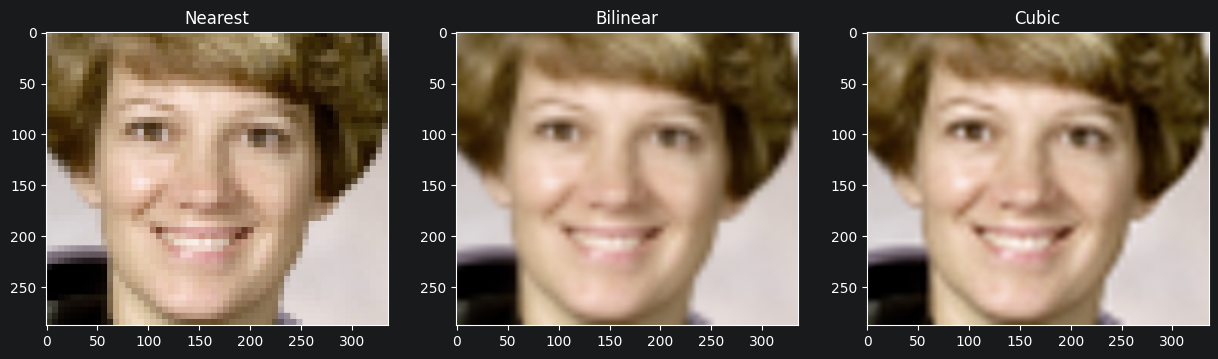

In [9]:
face_img_rgb = cv.cvtColor(cv.imread("face_small.png"), cv.COLOR_BGR2RGB)

face_enlarge_nearest_6x = cv.resize(
        face_img_rgb,
        dsize=None,
        fx=6,
        fy=6,
        interpolation=cv.INTER_NEAREST
)
face_enlarge_bilinear_6x = cv.resize(
        face_img_rgb,
        dsize=None,
        fx=6,
        fy=6,
        interpolation=cv.INTER_LINEAR
)
face_enlarge_cubic_6x = cv.resize(
        face_img_rgb,
        dsize=None,
        fx=6,
        fy=6,
        interpolation=cv.INTER_CUBIC
)

## Plot the faces on three plots
_, (plt_1, plt_2, plt_3) = plt.subplots(1, 3, figsize=(15, 5))

plt_1.imshow(face_enlarge_nearest_6x, cmap="gray")
plt_1.set_title("Nearest")

plt_2.imshow(face_enlarge_bilinear_6x, cmap="gray")
plt_2.set_title("Bilinear")

plt_3.imshow(face_enlarge_cubic_6x, cmap="gray")
plt_3.set_title("Cubic")

## cubic on the float32 image
face_enlarge_cubic_6x_f32 = cv.resize(
        face_img_rgb.copy().astype(np.float32),
        dsize=None,
        fx=6,
        fy=6,
        interpolation=cv.INTER_CUBIC
)

u8_255_threshold = np.count_nonzero(face_enlarge_cubic_6x > 255)
u8_0_threshold = np.count_nonzero(face_enlarge_cubic_6x < 0)

f32_255_threshold = np.count_nonzero(face_enlarge_cubic_6x_f32 > 255)
f32_0_threshold = np.count_nonzero(face_enlarge_cubic_6x_f32 < 0)

assert sum([f32_0_threshold, f32_255_threshold]) > 0
assert sum([u8_255_threshold, u8_0_threshold]) == 0

In the `float32` instance, the minimum and maximum values are between `-3.4...e+38` and `3.4...e+38`, resizing can allow pixels to stretch beyond the <0 and 255> thresholds.

`uint8` doesn't allow for this, so all pixels are constrained between 0 and 255

Invented values: {np.uint8(2)}


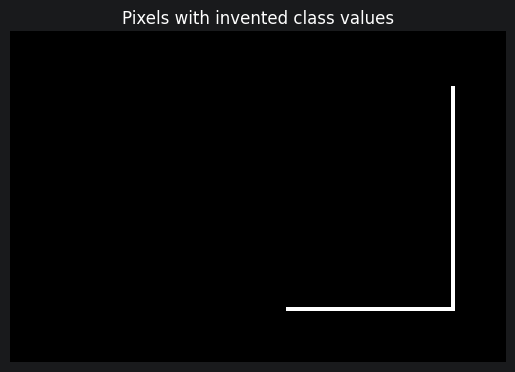

In [10]:
mask_img = cv.imread("mask.png", cv.IMREAD_GRAYSCALE)

mask_linear = cv.resize(
        mask_img,
        (126, 84),
        interpolation=cv.INTER_LINEAR,
)

mask_nearest = cv.resize(
        mask_img,
        (126, 84),
        interpolation=cv.INTER_NEAREST,
)

valid_classes = {0, 1, 3}
mask_linear_classes = set(np.unique(mask_linear))
mask_nearest_classes = set(np.unique(mask_nearest))

# Assert that the nearest classes are exactly {0, 1, 3}
assert mask_nearest_classes == valid_classes

invented_values = mask_linear_classes - valid_classes
print("Invented values:", invented_values)
assert len(invented_values) > 0

invented_mask = ~np.isin(mask_linear, list(valid_classes))
assert np.count_nonzero(invented_mask) > 0

highlight_mask = invented_mask.astype(np.uint8) * 255

plt.imshow(highlight_mask, cmap="gray")
plt.title("Pixels with invented class values")
plt.axis("off")
plt.show()

Text(0.5, 1.0, 'Gaussian Blur + shrinking')

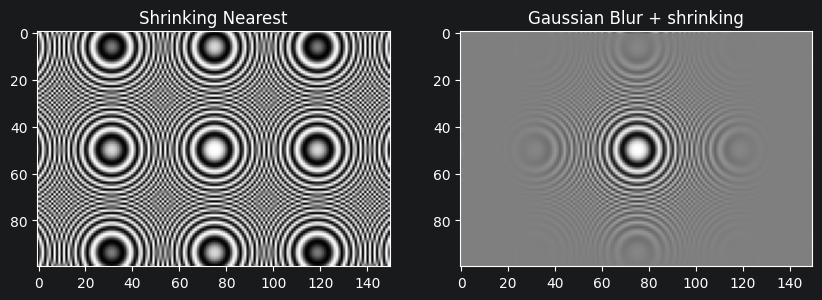

In [11]:
# Stretch section.
# Blurring with Gaussian Blur, then resizing
gaussian_blurred = cv.GaussianBlur(zone_plate_img, (0, 0), sigmaX=1.5)
shrunk_blurred = cv.resize(
        gaussian_blurred,
        (150, 100),
        interpolation=cv.INTER_NEAREST,
)

_, (plt_1, plt_2) = plt.subplots(1, 2, figsize=(10, 5))

plt_1.imshow(zone_plate_shrink_nearest, cmap="gray", vmin=0, vmax=255)
plt_1.set_title("Shrinking Nearest")
plt_2.imshow(shrunk_blurred, cmap="gray", vmin=0, vmax=255)
plt_2.set_title("Gaussian Blur + shrinking")